In [1]:
import os
import sys
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, timezone

from Legacy.Binance_new import Binance # Get_Price_Data_By_Time

# import importlib
# import RL_Trade_POC_Util

# # Reload the module
# importlib.reload(RL_Trade_POC_Util)

from RL_Trade_POC_Util import normalize, get_level, get_change, get_volatility, plot_array, plot_array1, plot_arrays

In [2]:
bn = Binance.instantiate(connected=False)

Initializing Binance singleton...


In [3]:
# Get_Price_Data_By_Time function seamlessly collects/creates price candles from Binance.
datatype = "klines" # "aggTrades" #, "klines"
symbol = "BTCUSDT"      # Any pair listed on Binance.

# dates that worked
# start = datetime(2018, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
# end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

start = datetime(2026, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

interval = '1m'    # in '1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '6h', '8h', '12h', '1d'.  (excludes: '3d', '1w')
print(f"interval: {interval}")
prePad = True           # prepend with null candles.
#------------------------------------------------------------------------------------------------------------------
candles, nFills, successful, _, reason = bn.Get_Price_Data_By_Time(datatype, symbol, interval, start, end, prePad=prePad)
print(reason)
if successful:          # price is a numpy array.
    print("\n Successful !!!!!!!!!! (nCandles, nAttributes) = {}, nCreated = {}".format(candles.shape, nFills))

interval: 1m
File not found: https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2026-03.zip
File not found: https://data.binance.vision/data/spot/daily/klines/BTCUSDT/1m/BTCUSDT-1m-2026-03-28.zip... total 0 candles created.
nCreated/nTotal/expected 0/120960/120960. 
Returning 10 columns: O H L C V, Quote V, nTrades, Buy base V, Buy quote V, Mark (0: original not forged)


 Successful !!!!!!!!!! (nCandles, nAttributes) = (120960, 10), nCreated = 0


In [18]:
n = 900

x = candles[:n, 3]   # closing price
v = candles[:n, 4]
x_normal = normalize(x, axis=0) * 2
v_normal = normalize(v, axis=0) * 2
back = 30           # we look back as far as 'back'

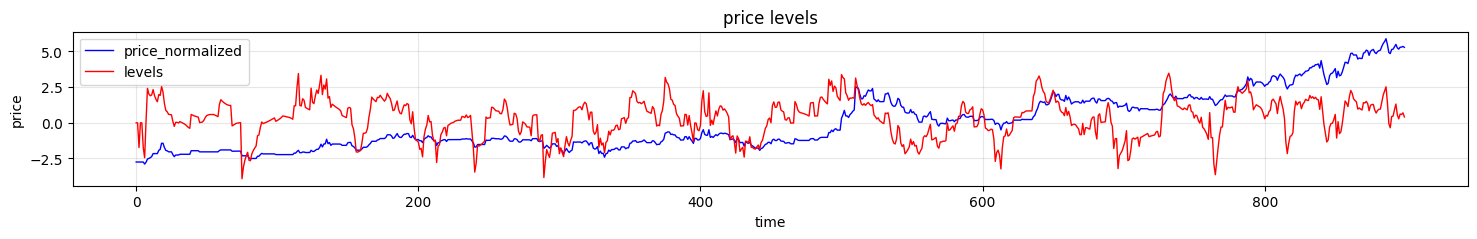

In [19]:

levels = []
for anchor in range(x.shape[0]):
    level = get_level(x, anchor, back, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([x_normal, levels], labels=['price_normalized', 'levels'], title="price levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

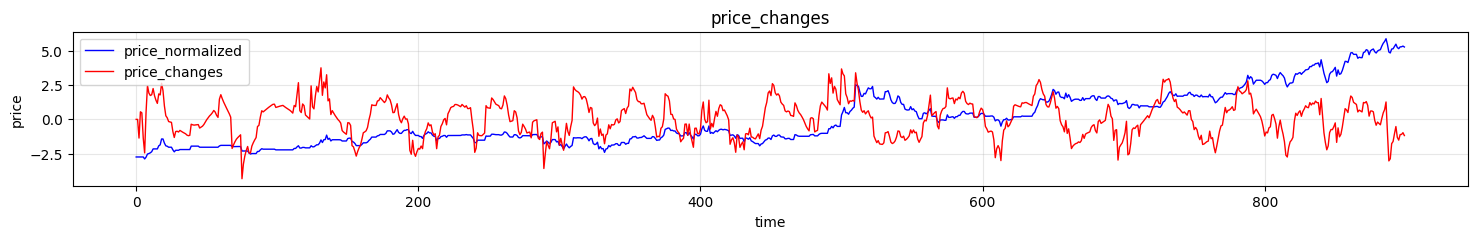

In [20]:
price_changes = []
for anchor in range(x.shape[0]):
    pc = get_change(x, anchor, back, axis=0)
    price_changes.append(pc)
price_changes = np.array(price_changes)
assert price_changes.shape == x.shape

plot_arrays([x_normal, price_changes], labels=['price_normalized', 'price_changes'], title="price_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


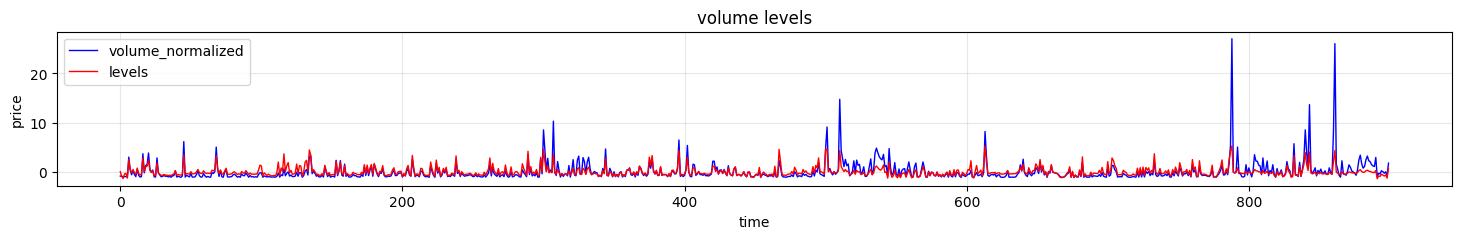

In [21]:
levels = []
for anchor in range(x.shape[0]):
    level = get_level(v, anchor, back, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([v_normal, levels], labels=['volume_normalized', 'levels'], title="volume levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

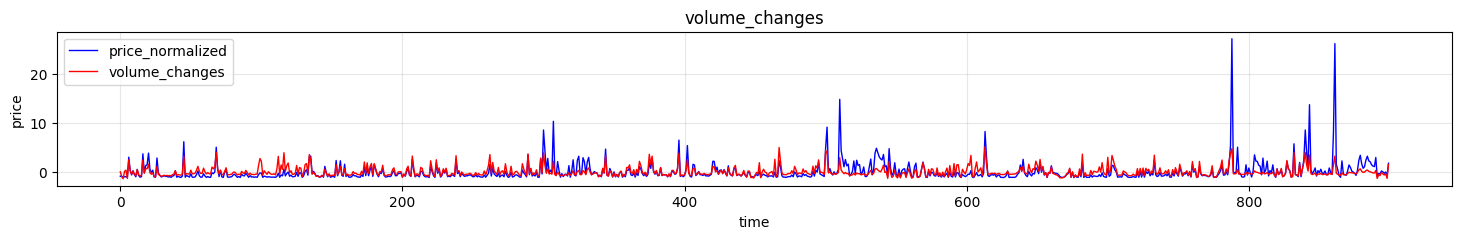

In [22]:
volume_changes = []
for anchor in range(v.shape[0]):
    vc = get_change(v, anchor, back, axis=0)
    volume_changes.append(vc)
volume_changes = np.array(volume_changes)
assert volume_changes.shape == v.shape

plot_arrays([v_normal, volume_changes], labels=['price_normalized', 'volume_changes'], title="volume_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


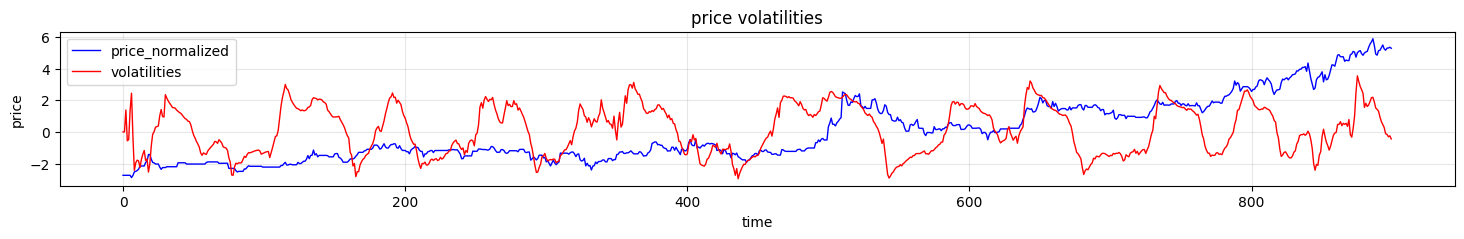

In [23]:
volatilities = []
for anchor in range(x.shape[0]):
    volatility = get_volatility(x, anchor, back, axis=0, span=back)
    volatilities.append(volatility)
volatilities = np.array(volatilities)
assert volatilities.shape == x.shape

plot_arrays([x_normal, volatilities], labels=['price_normalized', 'volatilities'], title="price volatilities", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


In [24]:
from enum import Enum

class Action(Enum):
    Buy = 'Buy'
    Hold = 'Hold'
    Sell = 'Sell'
    
def get_reward(action, price_curr, buy_costs):
    sell_reward = -1 if len(buy_costs) == 0 else -1 if sum(buy_costs) >= len(buy_costs) * price_curr else 1
    dict = { Action.Buy: 0, Action.Hold: 0, Action.Sell: sell_reward}
    reward = dict[action]
    return reward

def get_state(prices, volumes, buy_costs):
    max_buys = 10
    state = prices[-back:].tolist()
    state.append(get_level(prices, len(prices)-1, back, axis=0))
    state.append(get_change(prices, len(prices)-1, back, axis=0))
    state.append(get_level(volumes, len(prices)-1, back, axis=0))
    state.append(get_change(volumes, len(prices)-1, back, axis=0))
    state.append(get_volatility(prices, len(prices)-1, back, span=back))
    state = state + buy_costs + [0 for _ in range(max_buys - len(buy_costs))]
    state = np.array(state)
    return state

def act(action, prices, volumes, buy_costs):
    reward = get_reward(action, prices[-1], buy_costs)
    state = get_state(prices, volumes, buy_costs)
    done = action == Action.Sell

    if action == Action.Buy: buy_costs.append(prices[-1])
    elif action == Action.Sell: buy_costs = []

    return state, reward, done, buy_costs

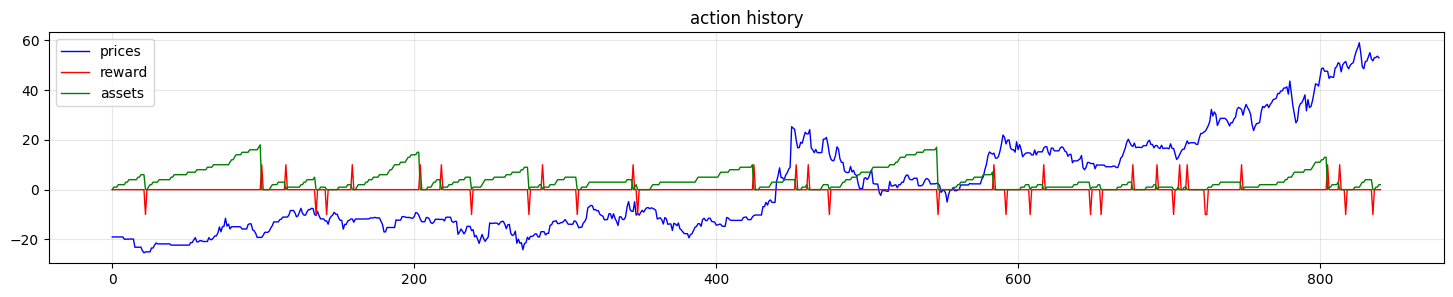

In [42]:
import random

buy_costs = []
actions = [Action.Buy] * 10 + [Action.Hold] * 50 + [Action.Sell] * 3

reward_history = []
asset_history = []

for t in range(len(x) + 1):
    if t < 2 * back: continue
    
    action = random.choice(actions)
    prices = x_normal[:t+1]
    volumes = v[:t+1]
    
    state, reward, done, buy_costs = act(action, prices, volumes, buy_costs)
    reward_history.append(reward)
    asset_history.append(len(buy_costs))
    
arrays = [x_normal[2 * back : ] * 10, np.array(reward_history) * 10, np.array(asset_history)]
labels = ['prices', 'reward', 'assets']
plot_arrays(arrays, labels, title="action history", xlabel="", ylabel="", figsize=(18, 3), flip=False, save_path=None)